In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

np.random.seed(0)
%matplotlib inline
print("numpy:", np.__version__, "| torch:", torch.__version__)

numpy: 2.5.5 | torch: 2.15.0


In [2]:
class MSELoss:
    def forward(self, pred, target):
        """
        L = (1/N) * sum((pred - target)^2)
        аргумент:
            pred   : загварын таамаглал, (m, k) хэлбэртэй
            target : жинхэнэ утга, pred-тэй ижил хэлбэртэй
        Буцаах нь:
            loss : скаляр
        """
        pred = np.asarray(pred, dtype=np.float64)
        target = np.asarray(target, dtype=np.float64)
        # (m,1) ба (m,) хэлбэр холилдвол numpy үүнийг (m,m) болгож broadcast хийгээд
        # алдаа заахгүйгээр буруу loss гаргадаг. Тиймээс эхлээд шалгана.
        assert pred.shape == target.shape, f"хэлбэр зөрж байна: {pred.shape} vs {target.shape}"

        self.pred = pred          # backward-д хэрэгтэй
        self.target = target
        return np.mean((pred - target) ** 2)

    def backward(self):
        """
        dL/dpred = 2 * (pred - target) / N
        Буцаах нь:
            grads : pred-тэй ижил хэлбэртэй градиент
        """
        N = self.pred.size        # нийт элемент (m * k), len() биш
        return 2 * (self.pred - self.target) / N

In [3]:
mse = MSELoss()
pred = np.array([[1.0], [2.0], [3.0]])
target = np.array([[1.0], [1.0], [1.0]])

print("loss :", mse.forward(pred, target))
print("grads:", mse.backward().ravel())

loss : 1.6666666666666667
grads: [0.         0.66666667 1.33333333]


In [4]:
def numerical_grad(loss_fn, pred, target, eps=1e-6):
    grad = np.zeros_like(pred)
    for idx in np.ndindex(pred.shape):
        old = pred[idx]
        pred[idx] = old + eps
        plus = loss_fn.forward(pred, target)
        pred[idx] = old - eps
        minus = loss_fn.forward(pred, target)
        pred[idx] = old          # хуучин утгыг нь буцааж тавина
        grad[idx] = (plus - minus) / (2 * eps)
    return grad


pred = np.random.randn(8, 3)
target = np.random.randn(8, 3)

mse.forward(pred, target)
g_analytic = mse.backward()
g_numeric = numerical_grad(mse, pred.copy(), target)

rel_err = np.abs(g_analytic - g_numeric).max() / (np.abs(g_analytic).max() + 1e-12)
print("хамгийн их харьцангуй зөрүү:", rel_err)
print("таарч байна уу:", np.allclose(g_analytic, g_numeric, atol=1e-6))

хамгийн их харьцангуй зөрүү: 1.1756657289603096e-09
таарч байна уу: True


In [5]:
p = torch.tensor(pred, requires_grad=True)
t = torch.tensor(target)

loss_torch = torch.nn.MSELoss()(p, t)
loss_torch.backward()

loss_ours = mse.forward(pred, target)
grad_ours = mse.backward()

print(f"loss  -> бидний: {loss_ours:.6f} | torch: {loss_torch.item():.6f}")
print("градиентын хамгийн их зөрүү:", np.abs(grad_ours - p.grad.numpy()).max())

loss  -> бидний: 2.510879 | torch: 2.510879
градиентын хамгийн их зөрүү: 2.7755575615628914e-17


In [6]:
class Linear:
    """Лаб 5-6-ийн Linear давхарга (шууд + гэдрэг)."""
    def __init__(self, n_in, n_out):
        self.w = np.random.randn(n_in, n_out) * 0.1
        self.b = np.zeros((1, n_out))

    def forward(self, inp):
        self.inp = inp
        return inp @ self.w + self.b

    def backward(self, grads):
        # MSELoss.backward аль хэдийн 1/N-д хуваасан тул энд дахин хуваахгүй
        self.dw = self.inp.T @ grads
        self.db = grads.sum(axis=0, keepdims=True)
        return grads @ self.w.T

    def step(self, lr):
        self.w -= lr * self.dw
        self.b -= lr * self.db

In [7]:
X = np.random.uniform(-3, 3, size=(200, 1))
y = 3 * X + 2 + np.random.randn(200, 1) * 0.8

layer = Linear(1, 1)
loss_fn = MSELoss()
lr = 0.05
history = []

for epoch in range(150):
    out = layer.forward(X)
    loss = loss_fn.forward(out, y)
    history.append(loss)

    grad = loss_fn.backward()     # dL/d(out)
    layer.backward(grad)          # dL/dw, dL/db
    layer.step(lr)

print(f"сурсан w = {layer.w.item():.3f}, b = {layer.b.item():.3f}  (жинхэнэ нь 3, 2)")
print(f"эцсийн loss = {history[-1]:.4f}")

сурсан w = 2.974, b = 1.896  (жинхэнэ нь 3, 2)
эцсийн loss = 0.5674


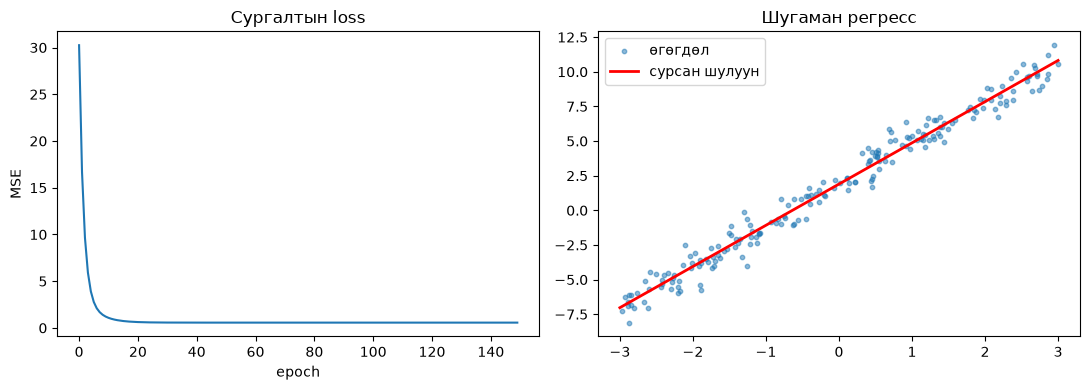

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(history)
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("MSE")
ax[0].set_title("Сургалтын loss")

xs = np.linspace(-3, 3, 50).reshape(-1, 1)
ax[1].scatter(X, y, s=10, alpha=0.5, label="өгөгдөл")
ax[1].plot(xs, layer.forward(xs), color="red", lw=2, label="сурсан шулуун")
ax[1].set_title("Шугаман регресс")
ax[1].legend()

plt.tight_layout()
plt.show()